In [226]:
import numpy as np
import matplotlib.pyplot as plt
from double_stopping_env import HouseSellingEnv, RandomWalk
import visualizer
from tabulate import tabulate
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.gridspec as gridspec

In [241]:
class QLearning:
    def __init__(self, env, epsilon=1, gamma=1, episodes=100000, alpha=0.9, c1=0, c2=0):
        self.env = env
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.episodes = episodes
        self.c1 = c1
        self.c2 = c2
        self.actions = [0, 1]
        self.start_states = []
        self.ep_rewards = []
        # Helper to convert state value to index, if needed
        self.state_to_idx = getattr(env, '_state_to_idx', {s: s for s in env.states})
        # Make the class robust by deriving num_states if not provided by the env
        # self.num_states = getattr(env, 'num_states', len(env.states))

        # Correctly size the Q-table to include a terminal step
        self.Q = np.zeros(
            (self.env.horizon + 1, len(self.env.states), 2, 2)
        )
        self.Q_values_history = np.zeros(
            (self.episodes, self.env.horizon + 1, len(self.env.states), 2, 2)
        )
        # Initialize Q-value for stopping action
        for t in range(self.env.horizon):
            for s_idx, s_val in enumerate(self.env.states):
                self.Q[t, s_idx, 1, 1] = s_val - self.env.cost # Stop with 2 stops left
                self.Q[t, s_idx, 0, 1] = s_val # Stop with 1 stop left

        # Set terminal state penalties at the now-valid index self.env.horizon
        self.Q[self.env.horizon, :, 0, :] = -self.c1
        self.Q[self.env.horizon, :, 1, :] = -self.c2
        
        self.training_regret = []
        self.optimal_policy = None

    def greedy(self, t, s_idx, z):
        """Chooses the best action, with random tie-breaking."""
        max_val = np.max(self.Q[t, s_idx, z - 1])
        # Find all actions that yield the maximum value
        max_actions = np.argwhere(self.Q[t, s_idx, z - 1] == max_val).flatten()
        # If there's more than one best action, choose one randomly
        if len(max_actions) > 1:
            return np.random.choice(max_actions)
        return max_actions[0]

    def e_greedy(self, t, s_idx, z):
        if np.random.rand() > self.epsilon:
            return self.greedy(t, s_idx, z)
        return np.random.choice(self.actions)

    def reward(self, s, action, z):
        if action == 0:  # Continue
            return -self.env.cost
        else:  # Stop
            if z == 2:  # first stop
                return s - self.env.cost
            elif z == 1:  # second stop
                return s
        return 0

    def simulate_episode(self):
        sequence = self.env.generate_sequence()
        # Ensure sequence is long enough, pad if necessary
        if len(sequence) < self.env.horizon:
            sequence.extend([sequence[-1]] * (self.env.horizon - len(sequence)))

        self.start_states.append(sequence[0])
        z = 2  # two stops available initially
        ep_reward = 0
        
        for t in range(self.env.horizon):
            s = sequence[t]
            s_idx = self.state_to_idx[s]
            a = self.e_greedy(t, s_idx, z)

            r = self.reward(s, a, z)
            ep_reward += r

            if t < self.env.horizon - 1:
                next_s = sequence[t + 1]
                next_s_idx = self.state_to_idx[next_s]
                next_z = z - 1 if a == 1 else z

                if next_z > 0:
                    next_max_q = np.max(self.Q[t + 1, next_s_idx, next_z - 1])
                else:
                    next_max_q = 0

                self.Q[t, s_idx, z - 1, a] += self.alpha * (
                    r + self.gamma * next_max_q - self.Q[t, s_idx, z - 1, a]
                )

                z = next_z
                if z == 0:
                    break
            else:
                self.Q[t, s_idx, z - 1, a] += self.alpha * (r - self.Q[t, s_idx, z - 1, a])
        
        self.ep_rewards.append(ep_reward)
    
    def update_history(self, episode):
        self.Q_values_history[episode] = self.Q.copy()

    def learn(self):
        for i in tqdm(range(self.episodes), desc="Learning Progress"):
            self.simulate_episode()
            self.update_history(i)
        self.extract_policy()
        return self.Q, self.Q_values_history

    def extract_policy(self):
        policy = np.zeros((self.env.horizon, len(self.env.states), 2), dtype=int)
        for t in range(self.env.horizon):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    policy[t, s, z - 1] = np.argmax(self.Q[t, s, z - 1])
        self.optimal_policy = policy
        return policy

    def get_values(self):
        V_1 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        V_2 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                V_1[t, s] = np.max(self.Q[t, s, 0, :])
                V_2[t, s] = np.max(self.Q[t, s, 1, :])
        return V_1, V_2

    def get_regret(self, V_2_optimal):
        self.training_regret = np.zeros(self.episodes)
        self.testing_regret = np.zeros(self.episodes)
        
        for episode in range(self.episodes):
            start_state_val = self.start_states[episode]
            start_state_idx = self.state_to_idx[start_state_val]
            self.training_regret[episode] = V_2_optimal[0][start_state_idx] - self.ep_rewards[episode]
            
            sequence = self.env.generate_sequence()
            if len(sequence) < self.env.horizon:
                sequence.extend([sequence[-1]] * (self.env.horizon - len(sequence)))
                
            start_state_val_test = sequence[0]
            start_state_idx_test = self.state_to_idx[start_state_val_test]
            z = 2
            ep_reward = 0
            
            for t in range(self.env.horizon):
                s = sequence[t]
                s_idx = self.state_to_idx[s]
                a = self.greedy(t, s_idx, z)
                r = self.reward(s, a, z)
                ep_reward += r
                if a == 1:
                    z -= 1
                if z == 0:
                    break
            self.testing_regret[episode] = V_2_optimal[0][start_state_idx_test] - ep_reward
            
        return self.training_regret, self.testing_regret

    def get_average_rewards(self):
        self.average_rewards = np.zeros(self.episodes)
        current_average = 0
        for i, reward in enumerate(self.ep_rewards):
            current_average += (reward - current_average) / (i + 1)
            self.average_rewards[i] = current_average
        return self.average_rewards


In [228]:
class MarkovianDoubleOptimalStopping:
    def __init__(self, env, gamma=1.0):
        self.env = env
        self.gamma = gamma
        self.N = env.horizon
        self.S = env.states
        self.cost = getattr(env, 'cost', 0)
        self.vN_1, self.vN_2 = self.dp()

    def dp(self):
        num_states = len(self.S)
        v = np.zeros((self.N + 1, 3, num_states))
        for n in range(1, self.N + 1):
            for s_idx, s_val in enumerate(self.S):
                exp_v_next_1 = np.dot(v[n - 1, 1, :], self.env.TPM[s_idx])
                exp_v_next_2 = np.dot(v[n - 1, 2, :], self.env.TPM[s_idx])
                # V1: One stop left.
                # Reward for stopping (second stop) = s
                # Reward for continuing = -cost
                stop_val_1 = s_val
                continuation_val_1 = -self.cost + self.gamma * exp_v_next_1
                v[n, 1, s_idx] = max(stop_val_1, continuation_val_1)

                # V2: Two stops left
                # Reward for stopping (first stop) = s - cost
                # Reward for continuing = -cost
                stop_val_2 = (s_val - self.cost) + self.gamma * exp_v_next_1
                continuation_val_2 = -self.cost + self.gamma * exp_v_next_2
                v[n, 2, s_idx] = max(stop_val_2, continuation_val_2)
        return v[:, 1, :], v[:, 2, :]

class DynamicMarkovianDoubleOptimalStopping(MarkovianDoubleOptimalStopping):
    def dp(self):
        num_states = len(self.S)
        v = np.zeros((self.N + 1, 3, num_states))
        for n in range(1, self.N + 1):
            t = self.N - n
            for s_idx, s_val in enumerate(self.S):
                current_tpm_row = self.env.TPMs[t][s_idx]
                exp_v_next_1 = np.dot(v[n - 1, 1, :], current_tpm_row)
                exp_v_next_2 = np.dot(v[n - 1, 2, :], current_tpm_row)
                # V1: One stop left.
                # Reward for stopping (second stop) = s
                # Reward for continuing = -cost
                stop_val_1 = s_val
                continuation_val_1 = -self.cost + self.gamma * exp_v_next_1
                v[n, 1, s_idx] = max(stop_val_1, continuation_val_1)

                # V2: Two stops left
                # Reward for stopping (first stop) = s - cost
                # Reward for continuing = -cost
                stop_val_2 = (s_val - self.cost) + self.gamma * exp_v_next_1
                continuation_val_2 = -self.cost + self.gamma * exp_v_next_2
                v[n, 2, s_idx] = max(stop_val_2, continuation_val_2)
        return v[:, 1, :], v[:, 2, :]


In [229]:
# import numpy as np
# import matplotlib.pyplot as plt
# from tabulate import tabulate

# class MarkovianDoubleOptimalStopping:
#     def __init__(self, env):
#         self.env = env
#         self.N = env.horizon
#         self.S = env.states
#         # Handle case where env might not have a cost attribute
#         self.cost = getattr(env, 'cost', 0)
#         self.vN_1, self.vN_2 = self.dp()

#     def dp(self):
#         """
#         Calculates the optimal value functions using backward induction (Dynamic Programming).
#         """
#         num_states = len(self.S)
#         # v[n, k, s] = Value with n periods remaining, k stops left, in state s.
#         # k=0 is unused, k=1 is for one stop, k=2 is for two stops.
#         v = np.zeros((self.N + 1, 3, num_states))

#         # Backward induction: iterate from n=1 (1 period left) to N (N periods left)
#         for n in range(1, self.N + 1):
#             for s_idx, s_val in enumerate(self.S):
#                 # --- Calculate expectations over the next state (which has n-1 periods left) ---
#                 # E[v(n-1, 1, S_next) | S_current = s_val]
#                 exp_v_next_1 = np.dot(v[n - 1, 1, :], self.env.TPM[s_idx])

#                 # E[v(n-1, 2, S_next) | S_current = s_val]
#                 exp_v_next_2 = np.dot(v[n - 1, 2, :], self.env.TPM[s_idx])

#                 # --- Update value function for k=1 (one stop left) ---
#                 # Action 1: Stop now. Value = current offer (s_val)
#                 stop_val_1 = s_val
#                 # Action 2: Continue. Value = expected future value minus cost
#                 continuation_val_1 = exp_v_next_1 - self.cost
#                 v[n, 1, s_idx] = max(stop_val_1, continuation_val_1)

#                 # --- Update value function for k=2 (two stops left) ---
#                 # Action 1: Stop now (use one stop). Value = s_val + value of remaining 1-stop problem
#                 stop_val_2 = s_val + exp_v_next_1
#                 # Action 2: Continue. Value = expected future value (with 2 stops) minus cost
#                 continuation_val_2 = exp_v_next_2 - self.cost
#                 v[n, 2, s_idx] = max(stop_val_2, continuation_val_2)

#         return v[:, 1, :], v[:, 2, :]

#     def plot(self, state_idx=50):
#         """Plot vN_1 and vN_2 over time for a fixed state."""
#         if state_idx < 0 or state_idx >= len(self.env.states):
#             raise IndexError(f"Invalid state index: {state_idx}. Must be in [0, {len(self.env.states) - 1}].")

#         time_to_go = np.arange(self.N + 1)

#         plt.figure(figsize=(10, 6))
#         plt.plot(time_to_go, self.vN_1[:, state_idx], label="$v(n, 1, s)$ (1 Stop Left)", marker="o")
#         plt.plot(time_to_go, self.vN_2[:, state_idx], label="$v(n, 2, s)$ (2 Stops Left)", marker="s")
#         plt.xlabel("n (Periods Remaining)")
#         plt.ylabel("Optimal Value")
#         plt.title(f"Optimal Stopping Values for State s = {self.S[state_idx]}")
#         plt.figtext(
#             0.5,
#             -0.05,
#             f"max_offer={self.env.max_offer}, cost={self.cost}, horizon={self.env.horizon}",
#             ha="center"
#         )
#         plt.legend()
#         plt.grid(True, which='both', linestyle='--', linewidth=0.5)
#         plt.show()

#     def print(self, state_idx):
#         """Prints a table of values for a specific state."""
#         if state_idx < 0 or state_idx >= len(self.env.states):
#             raise IndexError(f"Invalid state index: {state_idx}. Must be in [0, {len(self.env.states) - 1}].")

#         n_values = np.arange(self.N + 1)
#         table_data = [
#             [n, v1, v2]
#             for n, v1, v2 in zip(n_values, self.vN_1[:, state_idx], self.vN_2[:, state_idx])
#         ]
#         print(f"\n--- Optimal Values for State s = {self.S[state_idx]} ---")
#         print(tabulate(table_data, headers=["n (Periods Left)", "v(n, 1, s)", "v(n, 2, s)"], tablefmt="grid", floatfmt=".2f"))

#     def get_values(self):
#         """
#         This method appears to be for extracting a policy or transforming the value
#         function from 'time-to-go' to 'time-step'. It is left as is.
#         """
#         V_1 = np.zeros((self.N + 1, len(self.S)))
#         V_2 = np.zeros((self.N + 1, len(self.S)))

#         for t in range(self.N + 1):
#             n = self.N - t # Convert time step t to periods remaining n
#             if n < 0: continue
#             for s_idx, s_val in enumerate(self.S):
#                  # Get expected continuation value for the next time step (n-1)
#                 exp_v_next_1 = np.dot(self.vN_1[n - 1 if n > 0 else 0, :], self.env.TPM[s_idx])
#                 exp_v_next_2 = np.dot(self.vN_2[n - 1 if n > 0 else 0, :], self.env.TPM[s_idx])

#                 V_1[t, s_idx] = max(s_val, exp_v_next_1 - self.cost)
#                 V_2[t, s_idx] = max(s_val + exp_v_next_1, exp_v_next_2 - self.cost)

#         return V_1, V_2

# class DynamicMarkovianDoubleOptimalStopping(MarkovianDoubleOptimalStopping):
#     """ A specialized DP solver for environments with time-varying TPMs. """
#     def dp(self):
#         """ A specialized DP solver for environments with time-varying TPMs. """
#         num_states = len(self.S)
#         # v[n, k, s] = Value with n periods remaining, k stops left, in state s.
#         v = np.zeros((self.N + 1, 3, num_states))

#         # Backward induction: iterate from n=1 (1 period left) to N (N periods left)
#         for n in range(1, self.N + 1):
#             # The transition probabilities depend on the current time step 't'
#             t = self.N - n

#             for s_idx, s_val in enumerate(self.S):
#                 # Use the TPM specific to the current time step 't'
#                 # Assumes self.env.TPMs is a list or 3D array: TPMs[t] is the matrix for time t
#                 current_tpm_row = self.env.TPMs[t][s_idx]

#                 # --- Calculate expectations over the next state (which has n-1 periods left) ---
#                 # E_t[v(n-1, 1, S_next) | S_current = s_val]
#                 exp_v_next_1 = np.dot(v[n - 1, 1, :], current_tpm_row)

#                 # E_t[v(n-1, 2, S_next) | S_current = s_val]
#                 exp_v_next_2 = np.dot(v[n - 1, 2, :], current_tpm_row)

#                 # --- Update value function for k=1 (one stop left) ---
#                 stop_val_1 = s_val
#                 continuation_val_1 = exp_v_next_1 - self.cost
#                 v[n, 1, s_idx] = max(stop_val_1, continuation_val_1)

#                 # --- Update value function for k=2 (two stops left) ---
#                 # Stop value = current offer + expected value of the now-remaining 1-stop problem
#                 stop_val_2 = s_val + exp_v_next_1
#                 # Continuation value = expected value of the 2-stop problem at the next step
#                 continuation_val_2 = exp_v_next_2 - self.cost
#                 v[n, 2, s_idx] = max(stop_val_2, continuation_val_2)

#         # Return the entire value function tables, indexed by (periods_remaining, state_index)
#         # This is consistent with the previous correction.
#         # Other methods can transform this to a time-step based view if needed.
#         return v[:, 1, :], v[:, 2, :]
    
#     def get_values(self):
#         """
#         This method appears to be for extracting a policy or transforming the value
#         function from 'time-to-go' to 'time-step'. It is left as is.
#         """
#         V_1 = np.zeros((self.N + 1, len(self.S)))
#         V_2 = np.zeros((self.N + 1, len(self.S)))

#         for t in range(self.N + 1):
#             n = self.N - t # Convert time step t to periods remaining n
#             if n < 0: continue
#             for s_idx, s_val in enumerate(self.S):
#                  # Get expected continuation value for the next time step (n-1)
#                 exp_v_next_1 = np.dot(self.vN_1[n - 1 if n > 0 else 0, :], self.env.TPM[s_idx])
#                 exp_v_next_2 = np.dot(self.vN_2[n - 1 if n > 0 else 0, :], self.env.TPM[s_idx])

#                 V_1[t, s_idx] = max(s_val, exp_v_next_1 - self.cost)
#                 V_2[t, s_idx] = max(s_val + exp_v_next_1, exp_v_next_2 - self.cost)

#         return V_1, V_2

In [230]:
class MarkovianHouseSellingEnv_MaxOffer:
    def __init__(self, horizon=10, cost=10, max_offer=100, alpha=1.0):
        self.horizon = horizon
        self.cost = cost
        self.max_offer = max_offer
        self.states = [i for i in range(max_offer + 1)]
        self.actions = [0, 1]  # 0: Accept, 1: Reject
        self.alpha = alpha
        self._init_probabilities()
        self._init_TPM()

    def reset(self):
        return np.random.choice(self.states, p=self.P)

    def _init_probabilities(self):
        self.P = np.zeros(self.max_offer + 1)
        mu = self.max_offer / 2
        sigma = np.sqrt(self.max_offer / 4)
        for i in range(self.max_offer + 1):
            self.P[i] = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
                -((i - mu) ** 2) / (2 * sigma**2)
            )
        self.P /= np.sum(self.P)

    def _init_TPM(self):
        self.TPM = np.zeros((self.max_offer + 1, self.max_offer + 1))
        self.P_cumsum = np.cumsum(self.P)
        for s in range(self.max_offer + 1):
            for s_prime in range(self.max_offer + 1):
                if s_prime < s:
                    self.TPM[s, s_prime] = 0
                elif s_prime == s:
                    self.TPM[s, s_prime] = self.P_cumsum[s]
                else:
                    self.TPM[s, s_prime] = self.P[s_prime]
            if np.sum(self.TPM[s]) > 0:
                self.TPM[s] /= np.sum(self.TPM[s])

    def get_next_state(self, s):
        return np.random.choice(self.states, p=self.TPM[s])

    def generate_sequence(self):
        sequence = [self.reset()]
        for _ in range(1, self.horizon):
            next_state = self.get_next_state(sequence[-1])
            sequence.append(next_state)
        return sequence
    
    def exp_max(self, x, s):
        """
        Conditional expected maximum:
        E_s[max(x, S_{t+1}) | S_t = s] = sum_{s'} max(x, s') * P(s' | s)
        """
        vals = np.array([max(x, s_prime) for s_prime in self.states])
        return np.dot(vals, self.TPM[s])

    # Optional utilities if needed
    def cdf(self):
        return np.cumsum(self.P)

    def exp_indictor_less_than(self, x):
        vals = np.array([i if i <= x else 0 for i in self.states])
        return np.dot(vals, self.P)


In [231]:

class MarkovianHouseSellingEnv:
    def __init__(self, horizon=10, cost=10, max_offer=100, alpha=1.0):
        self.horizon = horizon
        self.cost = cost
        self.max_offer = max_offer
        self.states = [i for i in range(max_offer + 1)]
        self.actions = [0, 1]  # 0: Accept, 1: Reject
        self.alpha = alpha
        self._init_probabilities()
        self._init_TPM()

    def reset(self):
        return np.random.choice(self.states, p=self.P)

    def _init_probabilities(self):
        self.P = np.zeros(self.max_offer + 1)
        mu = self.max_offer / 2
        sigma = np.sqrt(self.max_offer / 4)
        for i in range(self.max_offer + 1):
            self.P[i] = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
                -((i - mu) ** 2) / (2 * sigma**2)
            )
        self.P /= np.sum(self.P)

    def _init_TPM(self):
        """Transition matrix TPM[s][s'] = P(s' | s)"""
        self.TPM = np.zeros((self.max_offer + 1, self.max_offer + 1))
        self.P_cumsum = np.cumsum(self.P)

        for s in range(self.max_offer + 1):
            for s_prime in range(self.max_offer + 1):
                if s_prime < s:
                    self.TPM[s, s_prime] = 0
                elif s_prime == s:
                    self.TPM[s, s_prime] = self.P_cumsum[s]
                else:
                    self.TPM[s, s_prime] = self.P[s_prime]

            self.TPM[s] /= np.sum(self.TPM[s])  # Normalize each row

    def get_next_state(self, s):
        return np.random.choice(self.states, p=self.TPM[s])

    def generate_sequence(self):
        sequence = [self.reset()]
        for _ in range(1, self.horizon):
            next_state = self.get_next_state(sequence[-1])
            sequence.append(next_state)
        return sequence

    # Corrected Definition
    def exp_max(self, x, s):
        """
        Conditional expected maximum:
        E_s[max(x, S_{t+1}) | S_t = s] = sum_{s'} max(x, s') * P(s' | s)
        """
        vals = np.array([max(x, s_prime) for s_prime in self.states])
        return np.dot(vals, self.TPM[s])

    # Optional utilities if needed
    def cdf(self):
        return np.cumsum(self.P)

    def exp_indictor_less_than(self, x):
        vals = np.array([i if i <= x else 0 for i in self.states])
        return np.dot(vals, self.P)


In [232]:
class GeometricDecayEnv:
    """
    In this environment, the probability of transitioning to a higher offer
    decays geometrically with the size of the jump. Large jumps in price
    are exponentially less likely than small ones.

    Attributes:
        q (float): The decay factor (0 < q < 1). A smaller q means a
                   faster decay and makes large jumps less likely.
    """
    def __init__(self, horizon=10, cost=10, max_offer=100, q=0.9):
        self.horizon = horizon
        self.cost = cost
        self.max_offer = max_offer
        self.num_states = max_offer
        if not 0 < q < 1:
            raise ValueError("Decay factor q must be between 0 and 1.")
        self.q = q
        self.states = list(range(max_offer + 1))
        self.actions = [0, 1]  # 0: Accept, 1: Reject
        self._init_TPM()
        self.initial_dist = np.full(max_offer + 1, 1 / (max_offer + 1))

    def reset(self):
        """Resets the environment to a random initial offer."""
        return np.random.choice(self.states, p=self.initial_dist)

    def _init_TPM(self):
        """Initializes the Transition Probability Matrix (TPM)."""
        self.TPM = np.zeros((self.max_offer + 1, self.max_offer + 1))
        for s in self.states:
            # Calculate probabilities for jumping to a higher state s_prime
            for s_prime in range(s + 1, self.max_offer + 1):
                jump_size = s_prime - s
                self.TPM[s, s_prime] = self.q ** jump_size

            # The probability of staying at state s is the remaining probability
            prob_of_jump = np.sum(self.TPM[s, s + 1 :])
            self.TPM[s, s] = 1.0

            # Normalize the row to sum to 1
            row_sum = np.sum(self.TPM[s, :])
            if row_sum > 0:
                self.TPM[s, :] /= row_sum

    def get_next_state(self, s):
        """Get the next state based on the current state s."""
        return np.random.choice(self.states, p=self.TPM[s])

    def generate_sequence(self):
        """Generates a sequence of offers for one episode."""
        sequence = [self.reset()]
        for _ in range(1, self.horizon):
            next_state = self.get_next_state(sequence[-1])
            sequence.append(next_state)
        return sequence
    
    def exp_max(self, x, s):
        vals = np.array([max(x, s_prime) for s_prime in self.states])
        probabilities = self.TPM[s]
        return np.dot(vals, probabilities)

    def cdf(self):
        return np.cumsum(self.P)

    def exp_indicator_less_than(self, x):
        vals = np.array([s if s <= x else 0 for s in self.states])
        return np.dot(vals, self.P)

In [233]:
class StaticRandomTPMEnv:
    """
    An environment with a randomly generated Transition Probability Matrix (TPM)
    that remains static for the entire episode.

    The dynamics are random but stationary.

    Attributes:
        num_states (int): The number of states in the environment.
        horizon (int): The number of time steps in a single episode.
        states (np.ndarray): An array of possible states, [0, 1, ..., n-1].
        TPM (np.ndarray): A (num_states x num_states) stochastic matrix where
                          TPM[i, j] is the probability of transitioning from
                          state i to state j. This is fixed after initialization.
        P (np.ndarray): The initial state distribution.
    """
    def __init__(self, num_states=5, horizon=10):
        """
        Initializes the environment.

        Args:
            num_states (int): The total number of states.
            horizon (int): The length of an episode.
        """
        self.num_states = num_states
        self.horizon = horizon
        self.states = np.arange(num_states)
        self.TPM = self._create_random_tpm()
        # Initial state distribution (assumed uniform)
        self.P = np.full(self.num_states, 1 / self.num_states)
        
        # Internal state trackers
        self.current_time_step = 0
        self.current_state = np.random.choice(self.states, p=self.P)

    def _create_random_tpm(self):
        """
        Generates a single random (num_states x num_states) stochastic matrix.
        Each row is guaranteed to sum to 1.
        """
        # Create a matrix with random values from a uniform distribution [0, 1)
        tpm = np.random.rand(self.num_states, self.num_states)
        
        # Normalize each row to ensure the probabilities sum to 1
        row_sums = tpm.sum(axis=1, keepdims=True)
        # Avoid division by zero, though extremely unlikely with np.random.rand
        row_sums[row_sums == 0] = 1
        
        return tpm / row_sums

    def reset(self):
        """
        Resets the environment to a new random starting state and time 0.

        Returns:
            int: The initial state of the episode.
        """
        self.current_time_step = 0
        self.current_state = np.random.choice(self.states, p=self.P)
        return self.current_state

    def step(self):
        """
        Takes a single step in the environment using the static TPM.

        Returns:
            int or None: The next state, or None if the episode has ended.
        """
        if self.current_time_step >= self.horizon - 1:
            return None  # Episode has finished

        # Get the transition probabilities for the current state from the static TPM
        probabilities = self.TPM[self.current_state]
        
        # Choose the next state based on these probabilities
        self.current_state = np.random.choice(self.states, p=probabilities)
        self.current_time_step += 1
        
        return self.current_state

    def generate_sequence(self):
        """
        Runs a full episode and returns the sequence of states.

        Returns:
            list: A list of states visited during the episode.
        """
        sequence = [self.reset()]
        for _ in range(self.horizon - 1):
            next_state = self.step()
            if next_state is not None:
                sequence.append(next_state)
        return sequence

    # --- Utility Functions ---

    def exp_max(self, x, s):
        """
        Calculates the conditional expected maximum value:
        E[max(x, S_{t+1}) | S_t = s] = sum_{s'} max(x, s') * P(S_{t+1}=s' | S_t=s)
        
        Args:
            x (float): The value to compare against the next state.
            s (int): The current state (index).
            
        Returns:
            float: The calculated expected maximum.
        """
        # Create an array of max(x, s') for all possible next states s'
        vals = np.array([max(x, s_prime) for s_prime in self.states])
        # The transition probabilities from state s
        probabilities = self.TPM[s]
        return np.dot(vals, probabilities)

    def cdf(self):
        """
        Calculates the Cumulative Distribution Function of the initial state distribution.
        """
        return np.cumsum(self.P)

    def exp_indicator_less_than(self, x):
        """
        Calculates E[S * I(S <= x)] where S is drawn from the initial distribution P.
        """
        vals = np.array([s if s <= x else 0 for s in self.states])
        return np.dot(vals, self.P)


class DynamicRandomTPMEnv:
    """
    An environment where the Transition Probability Matrix (TPM) is randomly
    generated at each time step.

    The dynamics are random and non-stationary.

    Attributes:
        num_states (int): The number of states in the environment.
        horizon (int): The number of time steps in a single episode.
        states (np.ndarray): An array of possible states, [0, 1, ..., n-1].
        TPMs (np.ndarray): A (horizon x num_states x num_states) tensor where
                           TPMs[t] is the stochastic matrix for time step t.
        P (np.ndarray): The initial state distribution.
    """
    def __init__(self, num_states=5, horizon=10):
        """
        Initializes the environment.

        Args:
            num_states (int): The total number of states.
            horizon (int): The length of an episode.
        """
        self.num_states = num_states
        self.horizon = horizon
        self.states = np.arange(num_states)
        self.TPMs = self._create_dynamic_tpms()
        # Initial state distribution (assumed uniform)
        self.P = np.full(self.num_states, 1 / self.num_states)

        # Internal state trackers
        self.current_time_step = 0
        self.current_state = np.random.choice(self.states, p=self.P)

    def _create_dynamic_tpms(self):
        """
        Generates a new random TPM for each time step in the horizon.
        """
        tpms = np.zeros((self.horizon, self.num_states, self.num_states))
        for t in range(self.horizon):
            # Generate a new random matrix for time step t
            tpm_t = np.random.rand(self.num_states, self.num_states)
            
            # Normalize each row
            row_sums = tpm_t.sum(axis=1, keepdims=True)
            row_sums[row_sums == 0] = 1
            
            # Store the normalized TPM for this specific time step
            tpms[t] = tpm_t / row_sums
            
        return tpms

    def reset(self):
        """
        Resets the environment to a new random starting state and time 0.

        Returns:
            int: The initial state of the episode.
        """
        self.current_time_step = 0
        self.current_state = np.random.choice(self.states, p=self.P)
        return self.current_state

    def step(self):
        """
        Takes a single step using the TPM specific to the current time step.

        Returns:
            int or None: The next state, or None if the episode has ended.
        """
        if self.current_time_step >= self.horizon - 1:
            return None  # Episode has finished

        # Get the specific TPM for the current time step
        current_tpm = self.TPMs[self.current_time_step]
        
        # Get transition probabilities for the current state from that TPM
        probabilities = current_tpm[self.current_state]
        
        # Choose the next state
        self.current_state = np.random.choice(self.states, p=probabilities)
        self.current_time_step += 1
        
        return self.current_state

    def generate_sequence(self):
        """
        Runs a full episode and returns the sequence of states.

        Returns:
            list: A list of states visited during the episode.
        """
        sequence = [self.reset()]
        for _ in range(self.horizon - 1):
            next_state = self.step()
            if next_state is not None:
                sequence.append(next_state)
        return sequence

    # --- Utility Functions ---

    def exp_max(self, x, s, t):
        """
        Calculates the time-dependent conditional expected maximum value:
        E[max(x, S_{t+1}) | S_t = s] = sum_{s'} max(x, s') * P(S_{t+1}=s' | S_t=s, t)
        
        Args:
            x (float): The value to compare against the next state.
            s (int): The current state (index).
            t (int): The current time step.
            
        Returns:
            float: The calculated expected maximum.
        """
        if t >= self.horizon -1:
            # At the last step, the next state is not defined, return max with current
            return max(x,s)
            
        # Create an array of max(x, s') for all possible next states s'
        vals = np.array([max(x, s_prime) for s_prime in self.states])
        # The transition probabilities from state s at time t
        probabilities = self.TPMs[t][s]
        return np.dot(vals, probabilities)

    def cdf(self):
        """
        Calculates the Cumulative Distribution Function of the initial state distribution.
        """
        return np.cumsum(self.P)

    def exp_indicator_less_than(self, x):
        """
        Calculates E[S * I(S <= x)] where S is drawn from the initial distribution P.
        """
        vals = np.array([s if s <= x else 0 for s in self.states])
        return np.dot(vals, self.P)


# if __name__ == '__main__':
#     NUM_STATES = 4
#     HORIZON = 12

#     print("--- 1. Static Random TPM Environment ---")
#     print("The transition rules are random, but fixed for the whole sequence.")
#     static_env = StaticRandomTPMEnv(num_states=NUM_STATES, horizon=HORIZON)
#     static_sequence = static_env.generate_sequence()
#     print(f"Generated sequence: {static_sequence}")
#     # You can inspect the single, static TPM
#     # print("Static TPM:\n", np.round(static_env.TPM, 2))
#     print("\n" + "="*50 + "\n")

#     print("--- 2. Dynamic Random TPM Environment ---")
#     print("The transition rules change randomly at every time step.")
#     dynamic_env = DynamicRandomTPMEnv(num_states=NUM_STATES, horizon=HORIZON)
#     dynamic_sequence = dynamic_env.generate_sequence()
#     print(f"Generated sequence: {dynamic_sequence}")
#     # You can inspect the TPM for a specific time step, e.g., time step 0
#     # print("TPM for T=0:\n", np.round(dynamic_env.TPMs[0], 2))
#     # print("TPM for T=1:\n", np.round(dynamic_env.TPMs[1], 2))


In [ ]:
# mention in appendix -> numerical result for this 
# speedy Q learning for this env 
# vector of drift, funciton of state 

class MarketFluctuationEnv:
    """
    An environment that simulates the percentage fluctuation of an asset's value.

    The state represents the percentage change from a base value, and time is
    structured in quarter-day intervals. The transition dynamics are controlled
    by a uniform-like distribution with adjustable drift and spread.

    Attributes:
        horizon_days (int): The total number of days in the simulation horizon.
        drift (float): The directional bias for price movements. Positive values
                       favor increases, negative values favor decreases.
        spread (float): Controls the volatility by defining the max size of a
                        single-step price change. Must be a multiple of 0.5.
        states (np.ndarray): The array of possible percentage changes, from -10.0 to 10.0.
        time_steps (np.ndarray): The array of time steps in quarter-day increments.
        TPM (np.ndarray): The Transition Probability Matrix. TPM[i, j] is the
                          probability of moving from state i to state j.
    """
    def __init__(self, lower_limit=-10.0, upper_limit=10.0, horizon_days=10, drift=0.0, spread=1.0):
        """
        Initializes the market environment.

        Args:
            horizon_days (int): The number of days for the simulation.
            drift (float): The mean or drift of the random walk.
            spread (float): The width/volatility of the step distribution.
                            Recommended to be a multiple of 0.5.
        """
        if spread <= 0 or spread % 0.5 != 0:
            raise ValueError("Spread must be a positive multiple of 0.5.")

        self.horizon_days = horizon_days
        self.drift = drift
        self.spread = spread
        self.lower_limit = lower_limit
        self.upper_limit = upper_limit

        # 1. Initialize State Space (-10, -9.5, ..., 9.5, 10.0)
        self.states = np.arange(lower_limit, upper_limit + 0.5, 0.5)
        self.num_states = len(self.states)
        self._state_to_idx = {state: i for i, state in enumerate(self.states)}

        # 2. Initialize Time Space (0.0, 0.25, ..., (horizon-1).75)
        self.total_time_steps = horizon_days * 4
        self.time_steps = np.arange(0, horizon_days, 0.25)

        # 3. Build the Transition Probability Matrix
        self._init_TPM()

        # 4. Initialize internal state trackers
        self.current_time_idx = 0
        self.current_state_idx = self._state_to_idx[0.0] # Start at 0% change

    def _init_TPM(self):
        """
        Builds the Transition Probability Matrix based on drift and spread.
        """
        # Define the possible single-period steps based on spread
        # e.g., for spread=1.0, steps are [-1.0, -0.5, 0.0, 0.5, 1.0]
        possible_steps = np.arange(-self.spread, self.spread + 0.5, 0.5)

        # Apply drift to create a weighted (non-uniform) distribution
        # A linear tilt is applied: weight = 1 + drift * step_value
        weights = 1.0 + self.drift * possible_steps
        weights[weights < 0] = 0  # Ensure weights are non-negative

        # Normalize weights to get probabilities
        total_weight = np.sum(weights)
        if total_weight > 0:
            step_probabilities = weights / total_weight
        else:
            # If all weights are zero, fall back to a uniform distribution
            step_probabilities = np.ones_like(weights) / len(weights)

        # Create the TPM
        self.TPM = np.zeros((self.num_states, self.num_states))
        for s_idx, current_state in enumerate(self.states):
            for step, prob in zip(possible_steps, step_probabilities):
                # Calculate the potential next state
                next_state_raw = current_state + step
                # Apply boundaries: clip the state between lower_limit and upper_limit
                next_state_clipped = np.clip(next_state_raw, self.lower_limit, self.upper_limit)

                # Find the index of the resulting state
                next_s_idx = self._state_to_idx[next_state_clipped]

                # Add the probability to the TPM
                self.TPM[s_idx, next_s_idx] += prob

    def reset(self):
        """
        Resets the environment to the starting state (0.0) and time (0.0).

        Returns:
            tuple: A tuple containing the initial state (0.0) and time (0.0).
        """
        self.current_time_idx = 0
        self.current_state_idx = self._state_to_idx[0.0]
        return self.states[self.current_state_idx], self.time_steps[self.current_time_idx]

    def step(self):
        """
        Advances the environment by one time step.

        Returns:
            tuple: A tuple of (next_state, next_time) if the episode is not
                   done, otherwise (None, None).
        """
        if self.current_time_idx >= self.total_time_steps - 1:
            return None, None  # Episode is finished

        # Determine the next state based on the current state's transition probabilities
        probabilities = self.TPM[self.current_state_idx]
        self.current_state_idx = np.random.choice(self.num_states, p=probabilities)
        self.current_time_idx += 1

        state = self.states[self.current_state_idx]
        time = self.time_steps[self.current_time_idx]

        return state, time

    def generate_sequence(self):
        """
        Runs a full simulation and generates a sequence of states.

        Returns:
            list: A list of states representing the asset's fluctuation
                  over the entire time horizon.
        """
        state_history = []
        current_state, _ = self.reset()
        state_history.append(current_state)

        for _ in range(self.total_time_steps - 1):
            next_state, _ = self.step()
            if next_state is not None:
                state_history.append(next_state)

        return state_history
    
    def exp_max(self, x, s_val):
        s_idx = self._state_to_idx.get(s_val)
        if s_idx is None:
            raise ValueError(f"State value {s_val} not found in state space.")
        vals = np.array([max(x, s_prime) for s_prime in self.states])
        probabilities = self.TPM[s_idx]
        return np.dot(vals, probabilities)

    def cdf(self):
        return np.cumsum(self.P)

    def exp_indicator_less_than(self, x):
        vals = np.array([s if s <= x else 0 for s in self.states])
        return np.dot(vals, self.P)


# if __name__ == '__main__':
#     # --- Example Usage ---

#     # 1. Neutral market (zero drift), low volatility
#     print("--- 1. Neutral Market, Low Volatility (Drift=0, Spread=0.5) ---")
#     env_neutral = MarketFluctuationEnv(horizon_days=5, drift=0.0, spread=0.5)
#     sequence_neutral = env_neutral.generate_sequence()
#     print(f"Generated sequence: {[f'{x:.1f}' for x in sequence_neutral]}")
#     print("\n" + "="*50 + "\n")

#     # 2. Bullish market (positive drift), medium volatility
#     print("--- 2. Bullish Market, Medium Volatility (Drift=0.2, Spread=1.0) ---")
#     env_bullish = MarketFluctuationEnv(horizon_days=5, drift=0.2, spread=1.0)
#     sequence_bullish = env_bullish.generate_sequence()
#     print(f"Generated sequence: {[f'{x:.1f}' for x in sequence_bullish]}")
#     print("\n" + "="*50 + "\n")


#     # 3. Bearish market (negative drift), high volatility
#     print("--- 3. Bearish Market, High Volatility (Drift=-0.1, Spread=2.0) ---")
#     env_bearish = MarketFluctuationEnv(horizon_days=5, drift=-0.1, spread=2.0)
#     sequence_bearish = env_bearish.generate_sequence()
#     print(f"Generated sequence: {[f'{x:.1f}' for x in sequence_bearish]}")
#     print("\n" + "="*50 + "\n")


In [235]:
# --- Main Simulation and Plotting Function ---
def run_and_plot_for_env(env, env_name, episodes=50000, gamma=1, state_to_plot_idx=None):
    """Runs both DP and Q-Learning for a given environment and plots all results."""
    print(f"\n----- Running Simulations for: {env_name} -----")
    
    # --- 1. Solve with Dynamic Programming (Optimal Solution) ---
    print("Solving with Dynamic Programming...")
    if isinstance(env, DynamicRandomTPMEnv):
        dp_solver = DynamicMarkovianDoubleOptimalStopping(env, gamma=gamma)
    else:
        dp_solver = MarkovianDoubleOptimalStopping(env, gamma=gamma)
    
    # DP solver returns values indexed by n (periods remaining).
    # Reverse the time axis to align with Q-learning's t (time step).
    V1_opt = dp_solver.vN_1[::-1, :]
    V2_opt = dp_solver.vN_2[::-1, :]

    # --- 2. Solve with Q-Learning ---
    print("Solving with Q-Learning...")
    # Pass gamma and epsilon params for consistency with DP
    q_agent = QLearning(env, episodes=episodes, alpha=0.1)
    Q_final, Q_history = q_agent.learn()
    V1_q, V2_q = q_agent.get_values()

    # --- 3. Calculate Bellman Error ---
    print("Calculating true Bellman Error...")
    bellman_error_v1 = np.zeros(episodes)
    bellman_error_v2 = np.zeros(episodes)

    for i in tqdm(range(episodes), desc="Calculating Bellman Error"):
        q_hist_snap = Q_history[i]
        total_error_v1 = 0
        total_error_v2 = 0
        
        # Iterate over each state and time step to calculate the error
        for t in range(env.horizon - 1):
            # Get expected values from the next time step's Q-values
            # CORRECTED: axis=1 corresponds to the actions dimension in the (states, actions) slice
            v1_next = np.max(q_hist_snap[t + 1, :, 0, :], axis=1)
            v2_next = np.max(q_hist_snap[t + 1, :, 1, :], axis=1)

            if hasattr(env, 'TPMs'): # Dynamic Environment
                TPM_t = env.TPMs[t]
                E_v1_next = np.dot(v1_next, TPM_t.T)
                E_v2_next = np.dot(v2_next, TPM_t.T)
            else: # Static Environment
                TPM = env.TPM
                E_v1_next = np.dot(v1_next, TPM.T)
                E_v2_next = np.dot(v2_next, TPM.T)
                
            for s_idx, s_val in enumerate(env.states):
                # Bellman Backup for V1 (one stop left) - Cost of Continuation model
                value_stop_1 = s_val
                value_continue_1 = -env.cost + gamma * E_v1_next[s_idx]
                bellman_backup_v1 = max(value_stop_1, value_continue_1)
                
                # Bellman Backup for V2 (two stops left)
                value_stop_2 = s_val + gamma * E_v1_next[s_idx]
                value_continue_2 = -env.cost + gamma * E_v2_next[s_idx]
                bellman_backup_v2 = max(value_stop_2, value_continue_2)
                
                # Current Q-based values for this snapshot
                current_v1 = np.max(q_hist_snap[t, s_idx, 0, :])
                current_v2 = np.max(q_hist_snap[t, s_idx, 1, :])

                # Accumulate absolute errors
                total_error_v1 += abs(bellman_backup_v1 - current_v1)
                total_error_v2 += abs(bellman_backup_v2 - current_v2)

        # Average error over all states and time steps for this episode
        num_entries = (env.horizon - 1) * len(env.states)
        bellman_error_v1[i] = total_error_v1 / num_entries if num_entries > 0 else 0
        bellman_error_v2[i] = total_error_v2 / num_entries if num_entries > 0 else 0


    # --- 4. Plotting ---
    print("Generating plots...")
    fig = plt.figure(figsize=(18, 17))
    fig.suptitle(f'Analysis for {env_name}', fontsize=20, y=0.98)
    gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.25)

    # Plot Row 1: V2 Analysis
    ax1 = fig.add_subplot(gs[0, 0])
    im1 = ax1.imshow(V2_q[:-1, :].T, aspect='auto', cmap='viridis', origin='lower')
    ax1.set_title('Q-Learned Value Function (V2)', fontsize=14)
    ax1.set_xlabel('Time Step')
    ax1.set_ylabel('State Index')
    fig.colorbar(im1, ax=ax1, label='Value')

    ax2 = fig.add_subplot(gs[0, 1])
    im2 = ax2.imshow(V2_opt[:-1, :].T, aspect='auto', cmap='magma', origin='lower')
    ax2.set_title('Optimal DP Value Function (V2)', fontsize=14)
    ax2.set_xlabel('Time Step')
    ax2.set_ylabel('State Index')
    fig.colorbar(im2, ax=ax2, label='Value')

    # Plot Row 2: V1 Analysis
    ax3 = fig.add_subplot(gs[1, 0])
    im3 = ax3.imshow(V1_q[:-1, :].T, aspect='auto', cmap='viridis', origin='lower')
    ax3.set_title('Q-Learned Value Function (V1)', fontsize=14)
    ax3.set_xlabel('Time Step')
    ax3.set_ylabel('State Index')
    fig.colorbar(im3, ax=ax3, label='Value')

    ax4 = fig.add_subplot(gs[1, 1])
    im4 = ax4.imshow(V1_opt[:-1, :].T, aspect='auto', cmap='magma', origin='lower')
    ax4.set_title('Optimal DP Value Function (V1)', fontsize=14)
    ax4.set_xlabel('Time Step')
    ax4.set_ylabel('State Index')
    fig.colorbar(im4, ax=ax4, label='Value')

    # Plot Row 3: Comparisons
    ax5 = fig.add_subplot(gs[2, 0])
    state_to_plot_idx = len(env.states) // 2 if state_to_plot_idx is None else state_to_plot_idx
    time_axis = np.arange(env.horizon)
    ax5.plot(time_axis, V2_opt[:env.horizon, state_to_plot_idx], 'r-o', label=f'DP V2 (State {state_to_plot_idx})')
    ax5.plot(time_axis, V2_q[:env.horizon, state_to_plot_idx], 'r--s', label=f'Q-L V2 (State {state_to_plot_idx})')
    ax5.plot(time_axis, V1_opt[:env.horizon, state_to_plot_idx], 'b-o', label=f'DP V1 (State {state_to_plot_idx})')
    ax5.plot(time_axis, V1_q[:env.horizon, state_to_plot_idx], 'b--s', label=f'Q-L V1 (State {state_to_plot_idx})')
    ax5.set_title('DP vs. Q-Learning Value Comparison', fontsize=14)
    ax5.set_xlabel('Time Step')
    ax5.set_ylabel('Value')
    ax5.legend()
    ax5.grid(True)

    # Bellman Error plot
    ax6 = fig.add_subplot(gs[2, 1])
    ax6.plot(np.arange(episodes), bellman_error_v2, alpha=0.8, label='V2 Error')
    ax6.plot(np.arange(episodes), bellman_error_v1, alpha=0.8, label='V1 Error')
    ax6.set_title('Average Bellman Error vs. Episodes', fontsize=14)
    ax6.set_xlabel('Episode')
    ax6.set_ylabel('Average Error')
    # ax6.set_yscale('log')  # Removed log scale
    ax6.legend()
    ax6.grid(True)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()


----- Running Simulations for: House Selling Environment -----
Solving with Dynamic Programming...
Solving with Q-Learning...


Learning Progress: 100%|██████████| 5000/5000 [00:00<00:00, 10552.24it/s]


Calculating true Bellman Error...


Calculating Bellman Error: 100%|██████████| 5000/5000 [00:33<00:00, 149.51it/s]
/var/folders/js/n7mnpc4915x2hstjlmdjm3_m0000gn/T/ipykernel_15640/68800207.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])


Generating plots...


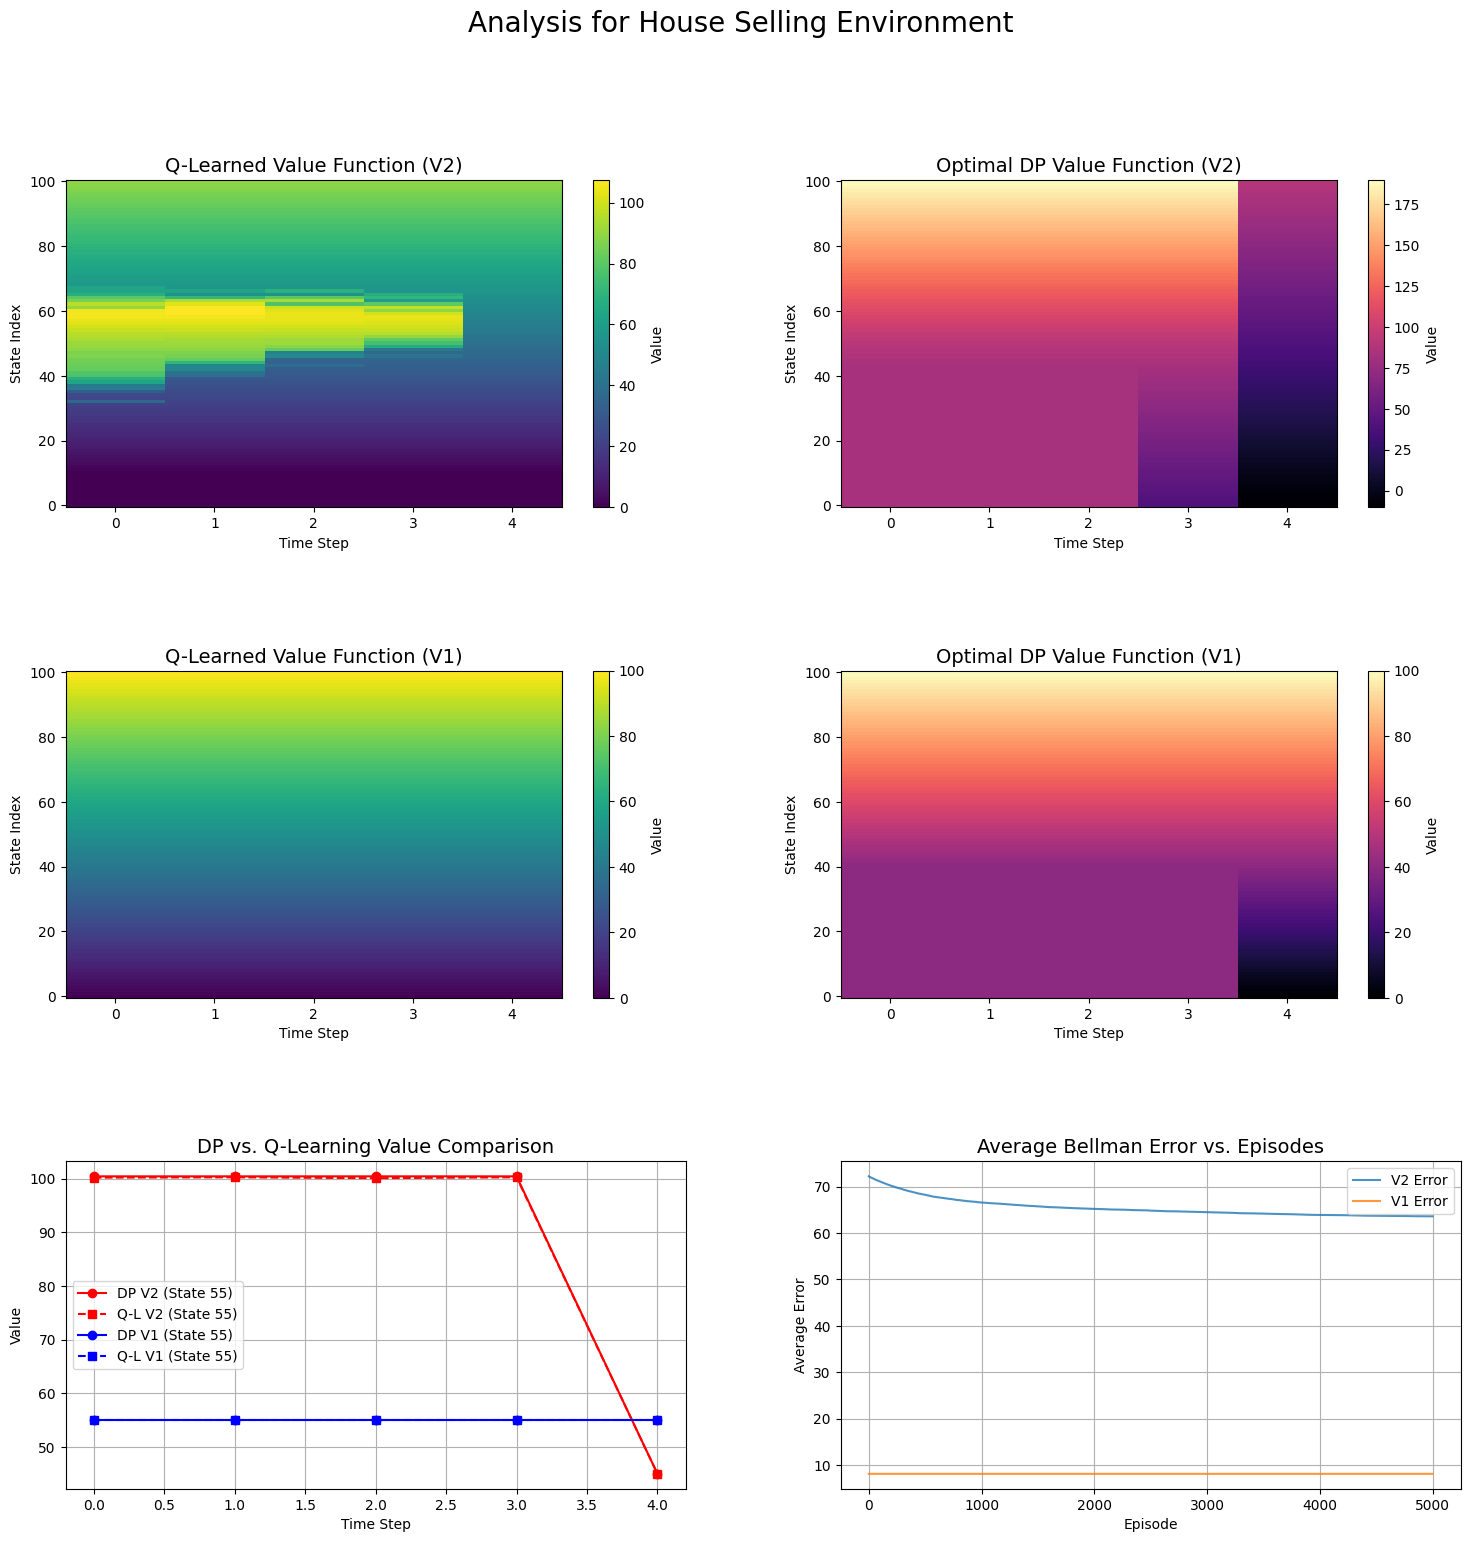

In [236]:
house_selling_env = MarkovianHouseSellingEnv_MaxOffer(horizon=5, cost=10, max_offer=100)
run_and_plot_for_env(house_selling_env, "House Selling Environment", episodes=5000, state_to_plot_idx=55)


----- Running Simulations for: Geometric Decay Environment -----
Solving with Dynamic Programming...
Solving with Q-Learning...


Learning Progress: 100%|██████████| 10000/10000 [00:01<00:00, 8162.64it/s]


Calculating true Bellman Error...


Calculating Bellman Error: 100%|██████████| 10000/10000 [00:08<00:00, 1241.05it/s]
/var/folders/js/n7mnpc4915x2hstjlmdjm3_m0000gn/T/ipykernel_15640/68800207.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])


Generating plots...


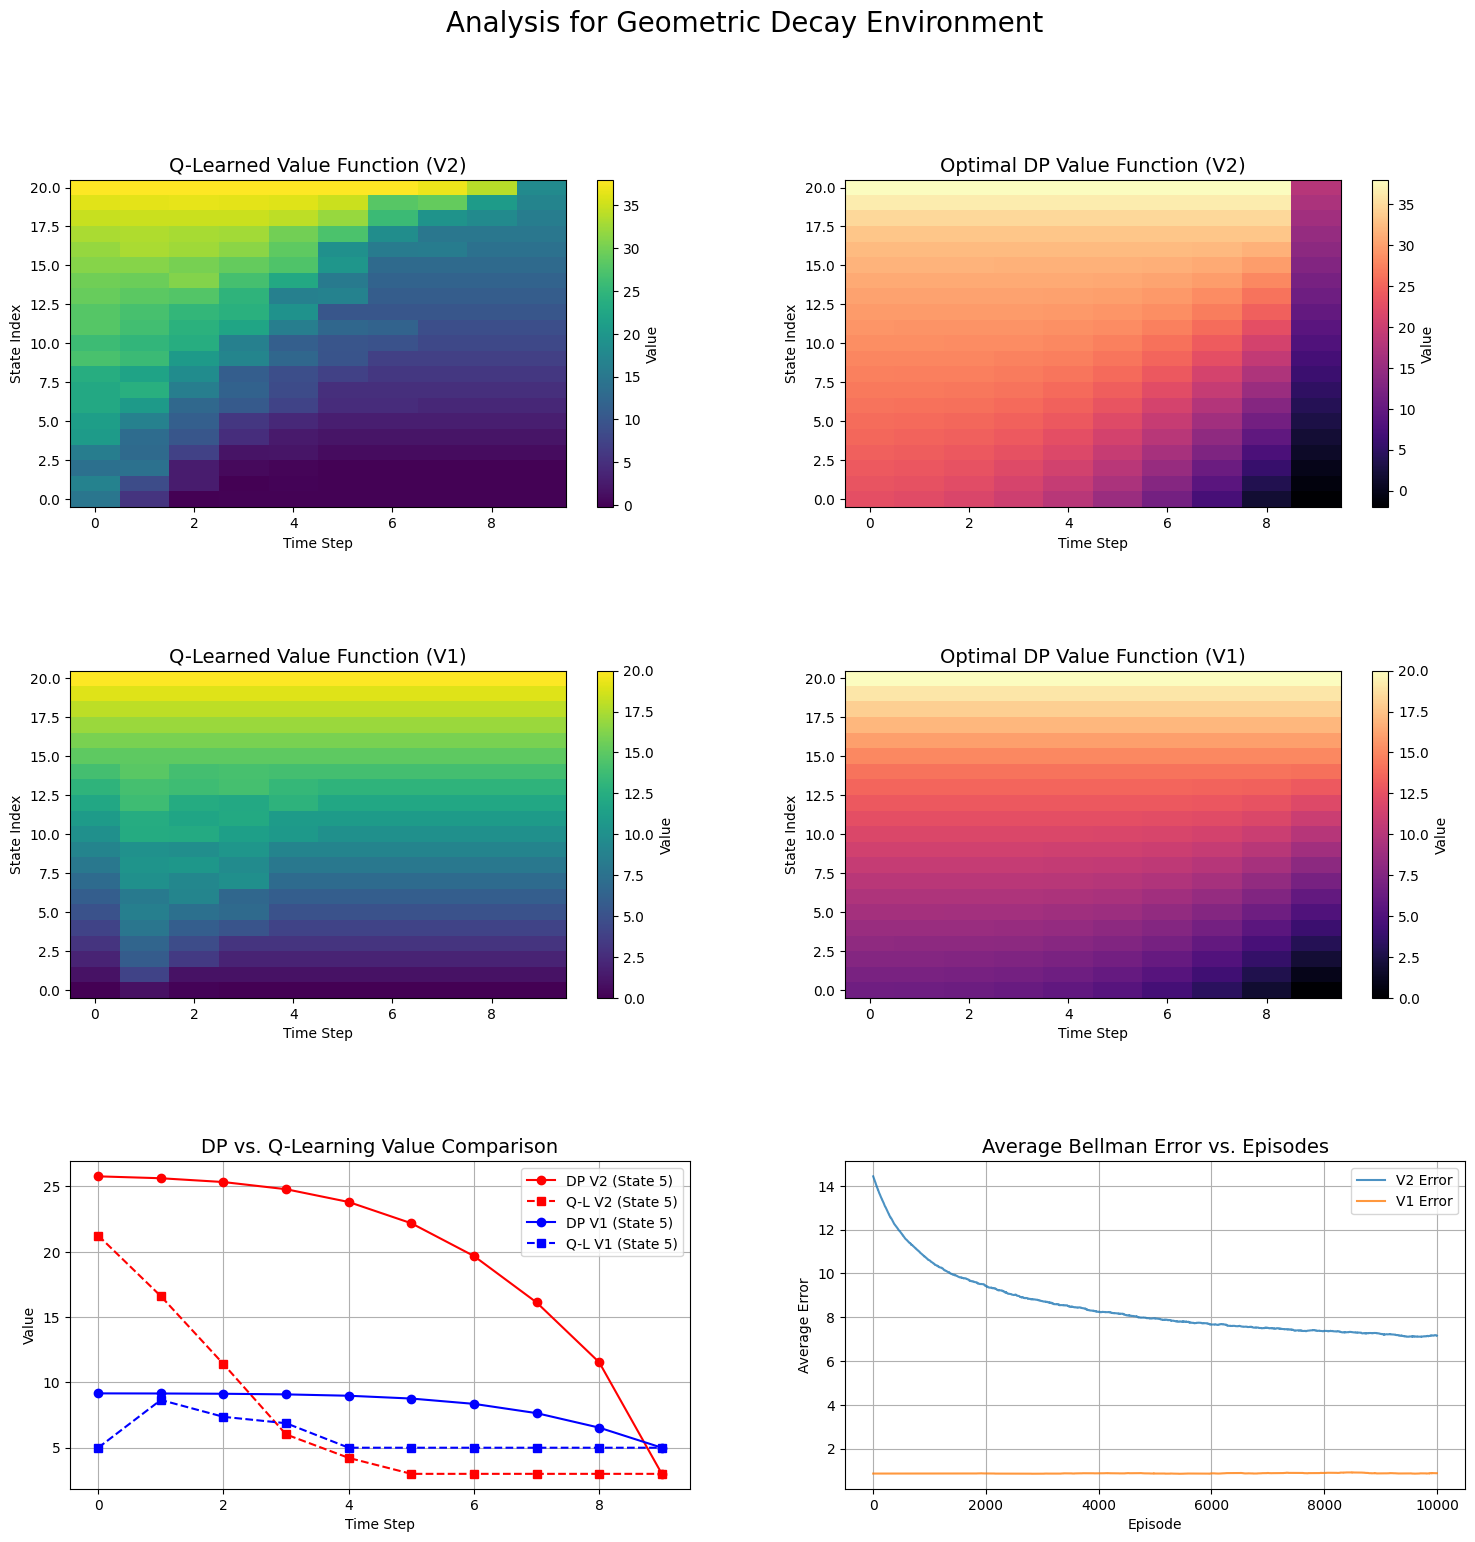

In [238]:

HORIZON = 10
EPISODES = 10000 # Use a smaller number for quick testing

# --- Environment 1: Geometric Decay ---
geo_env = GeometricDecayEnv(horizon=HORIZON, max_offer=20, q=0.8)
# Add a cost attribute for compatibility with algorithms
geo_env.cost = 2
run_and_plot_for_env(geo_env, "Geometric Decay Environment", episodes=EPISODES, state_to_plot_idx=5)



----- Running Simulations for: Market Fluctuation Environment -----
Solving with Dynamic Programming...
Solving with Q-Learning...


Learning Progress: 100%|██████████| 50000/50000 [00:04<00:00, 10659.05it/s]


Calculating true Bellman Error...


Calculating Bellman Error: 100%|██████████| 50000/50000 [00:32<00:00, 1539.40it/s]
/var/folders/js/n7mnpc4915x2hstjlmdjm3_m0000gn/T/ipykernel_15640/68800207.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])


Generating plots...


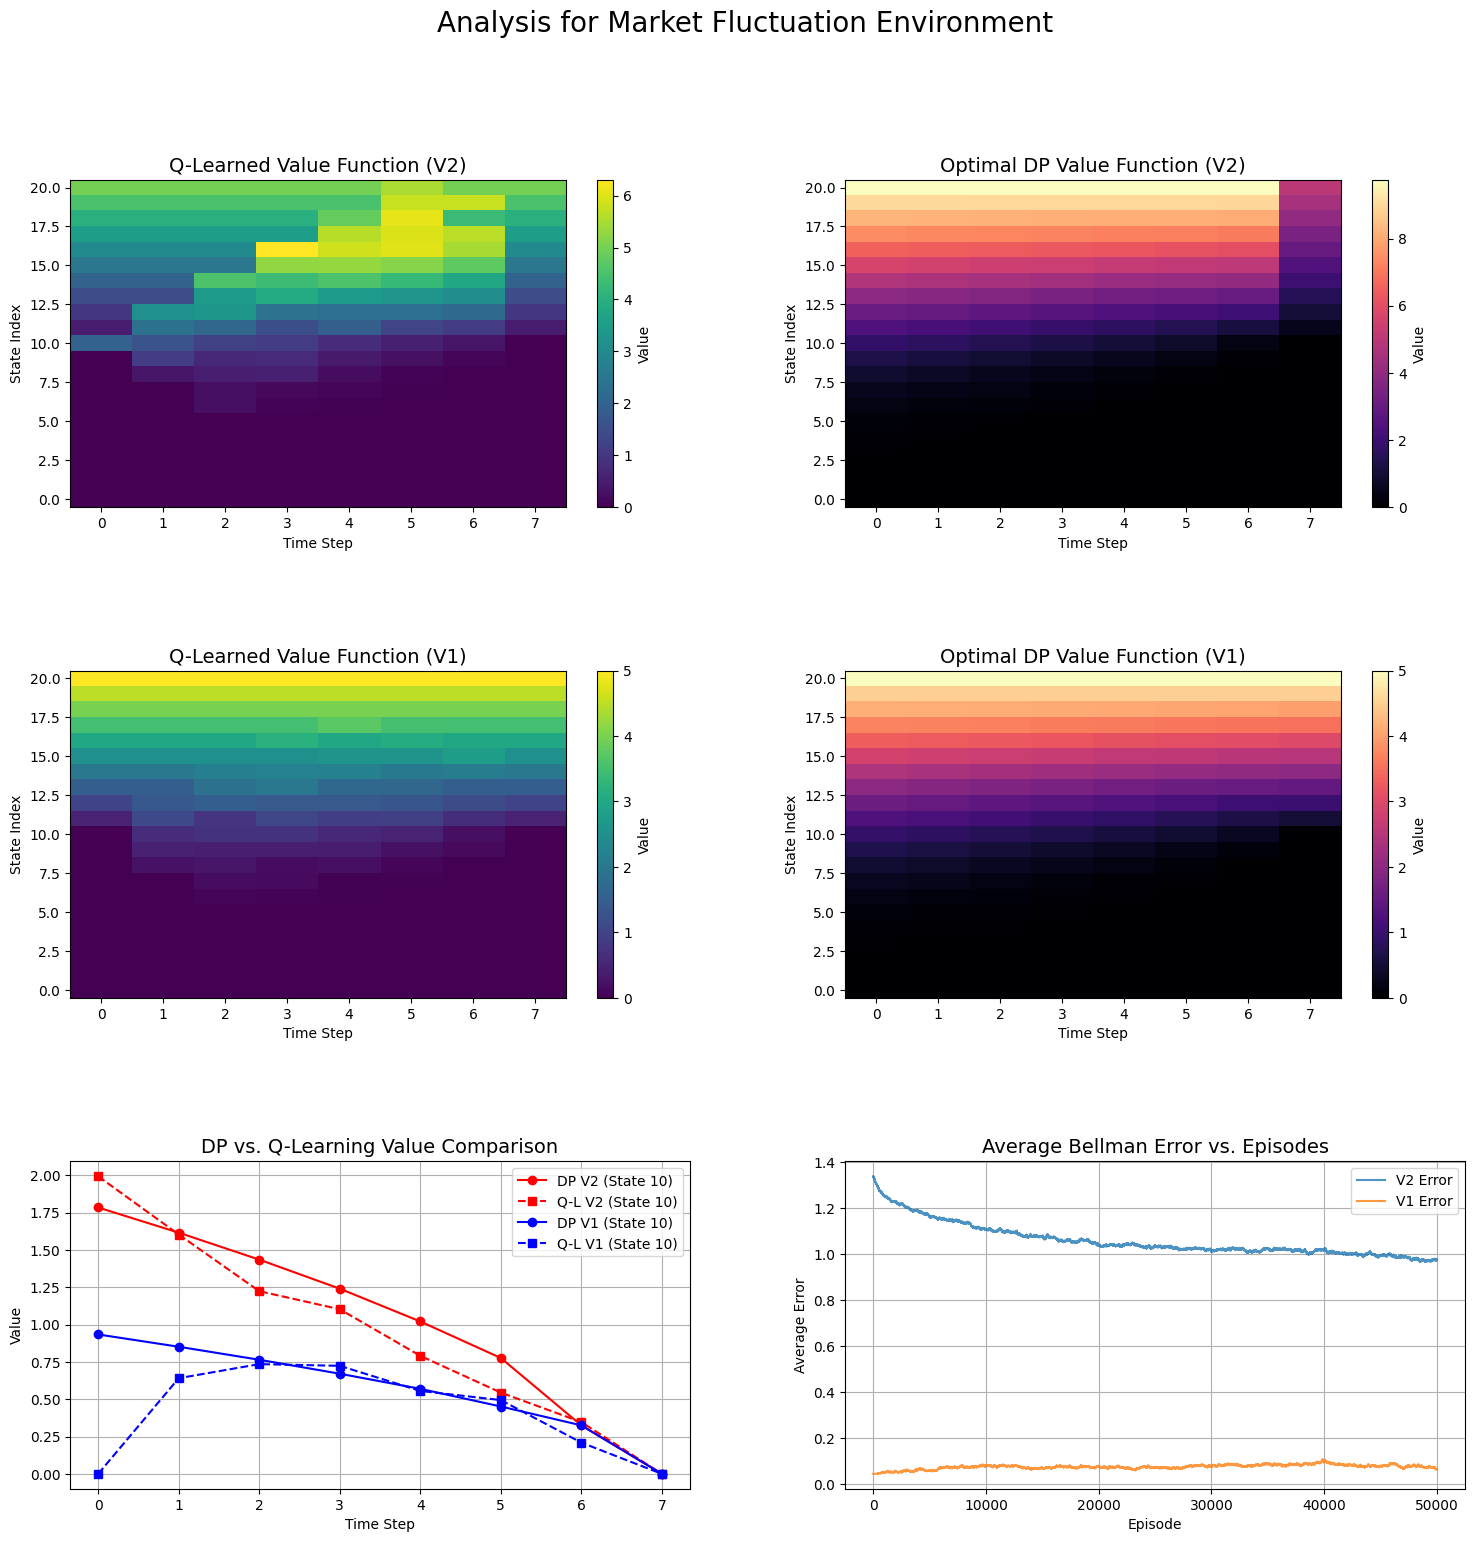

In [252]:

# --- Environment 2: Market Fluctuation ---
# The states are floats, but the algorithms are adapted to handle this via indices
market_env = MarketFluctuationEnv(lower_limit=-5, upper_limit=5, horizon_days=HORIZON//4, drift=0.1, spread=1.0)
market_env.cost = 0 # Example cost
market_env.horizon = market_env.total_time_steps # Align horizon
market_env.num_states = len(market_env.states) # Add num_states
run_and_plot_for_env(market_env, "Market Fluctuation Environment", episodes=EPISODES)



----- Running Simulations for: Static Random TPM Environment -----
Solving with Dynamic Programming...
Solving with Q-Learning...


Learning Progress: 100%|██████████| 50000/50000 [00:05<00:00, 9543.70it/s]


Calculating true Bellman Error...


Calculating Bellman Error: 100%|██████████| 50000/50000 [00:41<00:00, 1213.53it/s]
/var/folders/js/n7mnpc4915x2hstjlmdjm3_m0000gn/T/ipykernel_15640/68800207.py:137: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])


Generating plots...


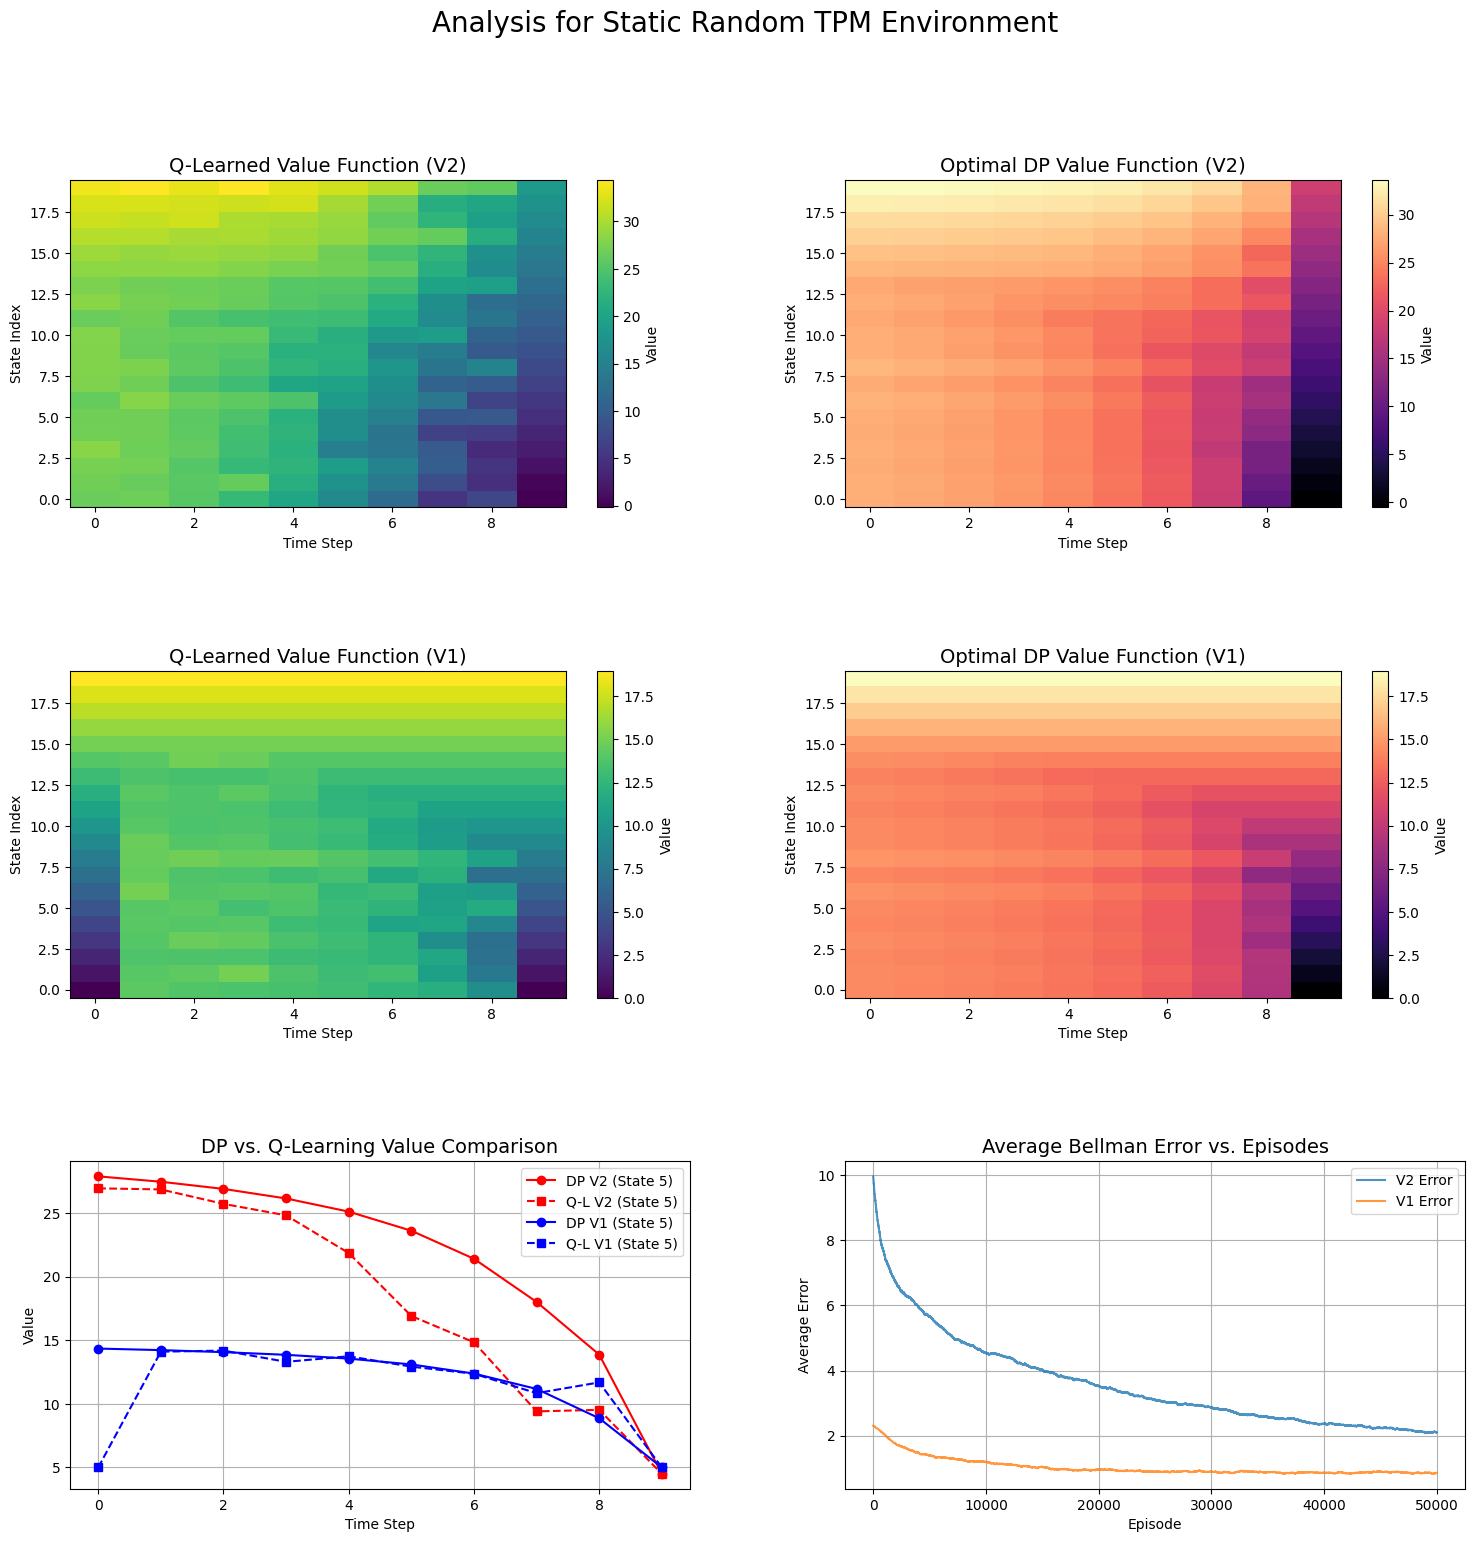

In [250]:
HORIZON=10
EPISODES=50000
# --- Environment 3: Static Random TPM ---
static_env = StaticRandomTPMEnv(num_states=20, horizon=HORIZON)
static_env.cost = 0.5
run_and_plot_for_env(static_env, "Static Random TPM Environment", episodes=EPISODES, state_to_plot_idx=5)


In [ ]:

# --- Environment 4: Dynamic Random TPM ---
dynamic_env = DynamicRandomTPMEnv(num_states=20, horizon=HORIZON)
dynamic_env.cost = 1
run_and_plot_for_env(dynamic_env, "Dynamic Random TPM Environment", episodes=EPISODES)
